In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120

PROJECT_ROOT = Path("/mnt/d/IDC409_Project15")
FIGURES_DIR  = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
DB_PATH      = PROJECT_ROOT / "data" / "processed" / "house_prices.db"
engine       = create_engine(f"sqlite:///{DB_PATH}")

AMES_PATH = PROJECT_ROOT / "data" / "raw" / "ames_housing" / "train.csv"
df = pd.read_csv(AMES_PATH)

print(f"Ames Housing dataset: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"Target column: SalePrice")
print(f"\nPrice range: ${df['SalePrice'].min():,.0f} – ${df['SalePrice'].max():,.0f}")
print(f"Median price: ${df['SalePrice'].median():,.0f}")

Ames Housing dataset: 1460 rows × 81 columns
Target column: SalePrice

Price range: $34,900 – $755,000
Median price: $163,000


In [2]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

print(f"Columns with missing values: {len(missing_df)}\n")
print(missing_df.to_string())

Columns with missing values: 19

              Missing Count  Missing %
PoolQC                 1453       99.5
MiscFeature            1406       96.3
Alley                  1369       93.8
Fence                  1179       80.8
MasVnrType              872       59.7
FireplaceQu             690       47.3
LotFrontage             259       17.7
GarageType               81        5.5
GarageYrBlt              81        5.5
GarageFinish             81        5.5
GarageQual               81        5.5
GarageCond               81        5.5
BsmtExposure             38        2.6
BsmtFinType2             38        2.6
BsmtQual                 37        2.5
BsmtCond                 37        2.5
BsmtFinType1             37        2.5
MasVnrArea                8        0.5
Electrical                1        0.1


In [3]:
# Drop columns where more than 40% of values are missing
# These columns can't be reliably imputed — too much guessing
threshold = 40.0
high_missing = missing_df[missing_df['Missing %'] > threshold].index.tolist()

print(f"Dropping {len(high_missing)} columns with >40% missing: {high_missing}")

df = df.drop(columns=['Id'] + high_missing)
print(f"\nShape after dropping: {df.shape}")

Dropping 6 columns with >40% missing: ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'FireplaceQu']

Shape after dropping: (1460, 74)


In [4]:
TARGET = 'SalePrice'
y = df[TARGET].copy()
X = df.drop(columns=[TARGET]).copy()

# Split into numeric and categorical
num_cols = X.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

print(f"Numeric features  : {len(num_cols)}")
print(f"Categorical features: {len(cat_cols)}")

# Fill numeric missing values with the median of that column
# Median is better than mean — one extreme value won't skew it
num_imputer = SimpleImputer(strategy='median')
X[num_cols] = num_imputer.fit_transform(X[num_cols])

# Fill categorical missing values with the word 'Unknown'
cat_imputer = SimpleImputer(strategy='constant', fill_value='Unknown')
X[cat_cols] = cat_imputer.fit_transform(X[cat_cols])

# Verify no missing values remain
remaining_missing = X.isnull().sum().sum()
print(f"\nRemaining missing values after imputation: {remaining_missing}")

Numeric features  : 36
Categorical features: 37

Remaining missing values after imputation: 0


/tmp/ipykernel_4850/3600338946.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns.tolist()


In [5]:
# One-hot encode all categorical columns
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

# Convert any bool columns to int
bool_cols = X_encoded.select_dtypes(include='bool').columns
X_encoded[bool_cols] = X_encoded[bool_cols].astype(int)

print(f"Features after encoding: {X_encoded.shape[1]} columns")

# Train/test split — same random_state as before for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

print(f"\nTraining set : {X_train.shape[0]} rows")
print(f"Test set     : {X_test.shape[0]} rows")
print(f"\nTraining median price : ${y_train.median():,.0f}")
print(f"Test median price     : ${y_test.median():,.0f}")

Features after encoding: 239 columns

Training set : 1168 rows
Test set     : 292 rows

Training median price : $165,000
Test median price     : $154,150


In [6]:
# Instead of repeating the same metric calculation 5 times,
# we write it once as a function and call it for each model

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    """
    Trains a model, evaluates on test set, and returns a results dict.
    
    MAE  = Mean Absolute Error    → average dollar error per house
    RMSE = Root Mean Square Error → penalises large errors more than MAE
    R²   = how much variance in price the model explains (1.0 = perfect)
    """
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    
    mae  = mean_absolute_error(y_te, y_pred)
    rmse = np.sqrt(mean_squared_error(y_te, y_pred))
    r2   = r2_score(y_te, y_pred)
    
    print(f"\n{'='*40}")
    print(f"Model : {name}")
    print(f"  MAE  : ${mae:>10,.0f}   (avg error per house)")
    print(f"  RMSE : ${rmse:>10,.0f}")
    print(f"  R²   :  {r2:>10.4f}   (1.0 = perfect)")
    
    return {
        'Model': name, 'MAE': mae, 'RMSE': rmse, 'R²': r2,
        'predictions': y_pred, 'fitted_model': model
    }

print("Helper function defined — ready to evaluate models.")

Helper function defined — ready to evaluate models.


In [7]:
# The baseline always predicts the mean house price
# Every other model must beat this — if it can't, it's useless

baseline = DummyRegressor(strategy='mean')
result_baseline = evaluate_model(
    "Baseline (mean)", baseline,
    X_train, y_train, X_test, y_test
)

print(f"\nBaseline always predicts: ${y_train.mean():,.0f}")
print("Any real model must have lower MAE and higher R² than this.")


Model : Baseline (mean)
  MAE  : $    62,576   (avg error per house)
  RMSE : $    87,619
  R²   :     -0.0009   (1.0 = perfect)

Baseline always predicts: $181,442
Any real model must have lower MAE and higher R² than this.


In [8]:
# Ridge = Linear Regression with L2 regularisation
# Regularisation prevents the model from fitting noise in the training data
# alpha controls how strong the regularisation is
# Higher alpha = simpler model, lower alpha = more complex model

# Ridge needs features on the same scale — we apply StandardScaler
# StandardScaler converts each feature to mean=0, std=1
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)   # use the SAME scaler, don't refit

ridge = Ridge(alpha=10.0)
result_ridge = evaluate_model(
    "Ridge Regression", ridge,
    X_train_scaled, y_train, X_test_scaled, y_test
)


Model : Ridge Regression
  MAE  : $    19,332   (avg error per house)
  RMSE : $    37,400
  R²   :      0.8176   (1.0 = perfect)


In [9]:
# Lasso = Linear Regression with L1 regularisation
# Key difference from Ridge: Lasso can shrink some feature weights to exactly 0
# This means Lasso performs automatic feature selection
# Features it zeros out are being told: "you don't help predict price"

lasso = Lasso(alpha=100.0, max_iter=5000)
result_lasso = evaluate_model(
    "Lasso Regression", lasso,
    X_train_scaled, y_train, X_test_scaled, y_test
)

# See how many features Lasso zeroed out
n_zero = (lasso.coef_ == 0).sum()
n_total = len(lasso.coef_)
print(f"\nLasso zeroed out {n_zero}/{n_total} features ({n_zero/n_total*100:.1f}%)")
print("These features were judged unhelpful for predicting price.")


Model : Lasso Regression
  MAE  : $    19,346   (avg error per house)
  RMSE : $    44,984
  R²   :      0.7362   (1.0 = perfect)

Lasso zeroed out 62/239 features (25.9%)
These features were judged unhelpful for predicting price.


In [10]:
# A Decision Tree learns if-then rules from the data
# Example rule: "If GrLivArea > 1500 AND Neighborhood is NridgHt → predict $300k"
# 
# max_depth limits how many rules deep the tree can go
# Without a limit, it memorises the training data perfectly (overfitting)
# but performs terribly on new houses it hasn't seen before

tree = DecisionTreeRegressor(max_depth=8, random_state=42)
result_tree = evaluate_model(
    "Decision Tree (depth=8)", tree,
    X_train, y_train, X_test, y_test
)


Model : Decision Tree (depth=8)
  MAE  : $    27,331   (avg error per house)
  RMSE : $    43,370
  R²   :      0.7548   (1.0 = perfect)


In [11]:
# Random Forest = hundreds of Decision Trees, each trained on a random subset
# of the data and random subset of features. Their predictions are averaged.
# This averaging cancels out individual trees' mistakes → much more accurate.

# ── First: K-Fold Cross Validation ──────────────────────────────────
# Instead of one 80/20 split, we do 5 different 80/20 splits
# Train on 4 folds, test on 1, rotate, repeat.
# The 5 R² scores give us a reliable estimate of true model performance.

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf, X_train, y_train, cv=kf, scoring='r2')

print("5-Fold Cross Validation R² scores:")
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {score:.4f}")
print(f"Mean R² : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print("\n(A consistent mean with low std = stable, trustworthy model)")

# ── Now train on full training set and evaluate on test set ─────────
result_rf = evaluate_model(
    "Random Forest (100 trees)", rf,
    X_train, y_train, X_test, y_test
)

5-Fold Cross Validation R² scores:
  Fold 1: 0.8814
  Fold 2: 0.7976
  Fold 3: 0.7803
  Fold 4: 0.8813
  Fold 5: 0.8624
Mean R² : 0.8406 ± 0.0431

(A consistent mean with low std = stable, trustworthy model)

Model : Random Forest (100 trees)
  MAE  : $    17,573   (avg error per house)
  RMSE : $    28,814
  R²   :      0.8918   (1.0 = perfect)


In [12]:
# Build a clean comparison table from all results
results = pd.DataFrame([
    {'Model': result_baseline['Model'], 'MAE': result_baseline['MAE'],
     'RMSE': result_baseline['RMSE'], 'R²': result_baseline['R²']},
    {'Model': result_ridge['Model'],    'MAE': result_ridge['MAE'],
     'RMSE': result_ridge['RMSE'],    'R²': result_ridge['R²']},
    {'Model': result_lasso['Model'],    'MAE': result_lasso['MAE'],
     'RMSE': result_lasso['RMSE'],    'R²': result_lasso['R²']},
    {'Model': result_tree['Model'],     'MAE': result_tree['MAE'],
     'RMSE': result_tree['RMSE'],     'R²': result_tree['R²']},
    {'Model': result_rf['Model'],       'MAE': result_rf['MAE'],
     'RMSE': result_rf['RMSE'],       'R²': result_rf['R²']},
]).set_index('Model')

results['MAE']  = results['MAE'].apply(lambda x: f"${x:,.0f}")
results['RMSE'] = results['RMSE'].apply(lambda x: f"${x:,.0f}")
results['R²']   = results['R²'].apply(lambda x: f"{x:.4f}")

print("=" * 65)
print("MODEL COMPARISON TABLE")
print("=" * 65)
print(results.to_string())
print("=" * 65)
print("\nBest model = highest R² + lowest MAE")

# Save as CSV for the report
results.to_csv(PROJECT_ROOT / "reports" / "model_comparison.csv")
print("Saved: reports/model_comparison.csv")

MODEL COMPARISON TABLE
                               MAE     RMSE       R²
Model                                               
Baseline (mean)            $62,576  $87,619  -0.0009
Ridge Regression           $19,332  $37,400   0.8176
Lasso Regression           $19,346  $44,984   0.7362
Decision Tree (depth=8)    $27,331  $43,370   0.7548
Random Forest (100 trees)  $17,573  $28,814   0.8918

Best model = highest R² + lowest MAE
Saved: reports/model_comparison.csv


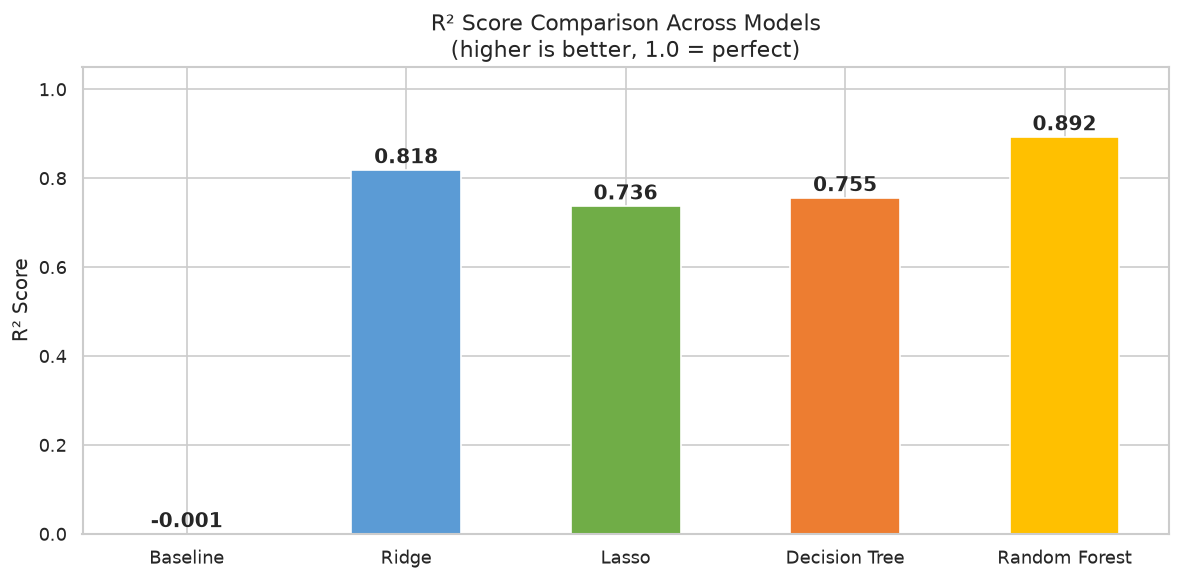

Saved: model_comparison_r2.png


In [13]:
# Rebuild results with raw numbers for plotting
results_plot = pd.DataFrame([
    {'Model': 'Baseline',      'R²': result_baseline['R²']},
    {'Model': 'Ridge',         'R²': result_ridge['R²']},
    {'Model': 'Lasso',         'R²': result_lasso['R²']},
    {'Model': 'Decision Tree', 'R²': result_tree['R²']},
    {'Model': 'Random Forest', 'R²': result_rf['R²']},
])

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#aaaaaa', '#5B9BD5', '#70AD47', '#ED7D31', '#FFC000']
bars = ax.bar(results_plot['Model'], results_plot['R²'], color=colors, width=0.5)

# Label each bar with its R² value
for bar, val in zip(bars, results_plot['R²']):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.005,
            f'{val:.3f}', ha='center', va='bottom', fontweight='bold')

ax.set_title('R² Score Comparison Across Models\n(higher is better, 1.0 = perfect)',
             fontsize=13)
ax.set_ylabel('R² Score')
ax.set_ylim(0, 1.05)
ax.axhline(y=0, color='red', linewidth=0.8, linestyle='--', label='Baseline R²=0')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison_r2.png", bbox_inches='tight')
plt.show()
print("Saved: model_comparison_r2.png")

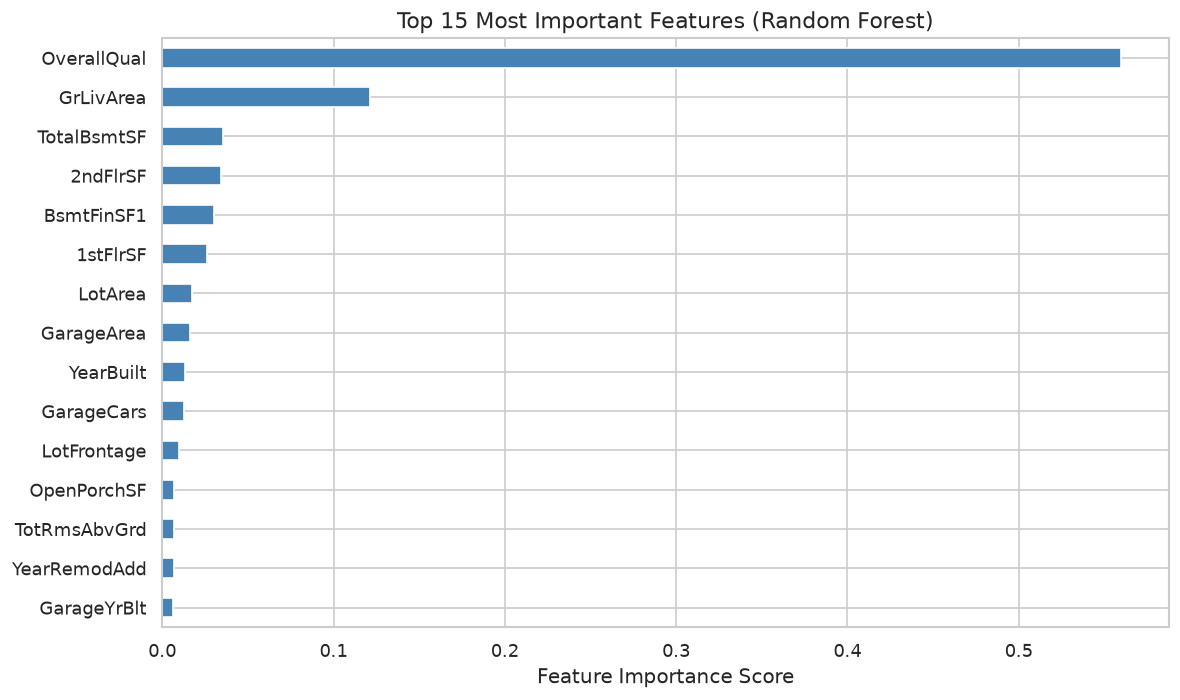

Top 5 most important features:
  OverallQual                    0.5596
  GrLivArea                      0.1214
  TotalBsmtSF                    0.0357
  2ndFlrSF                       0.0340
  BsmtFinSF1                     0.0302


In [14]:
# Feature importance tells us WHICH features the Random Forest
# found most useful when making its predictions
# This is one of the most useful outputs of the whole project

importances = pd.Series(
    result_rf['fitted_model'].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
importances.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Top 15 Most Important Features (Random Forest)', fontsize=13)
ax.set_xlabel('Feature Importance Score')
ax.invert_yaxis()  # most important at the top
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_importance_rf.png", bbox_inches='tight')
plt.show()

print("Top 5 most important features:")
for feat, score in importances.head(5).items():
    print(f"  {feat:<30} {score:.4f}")

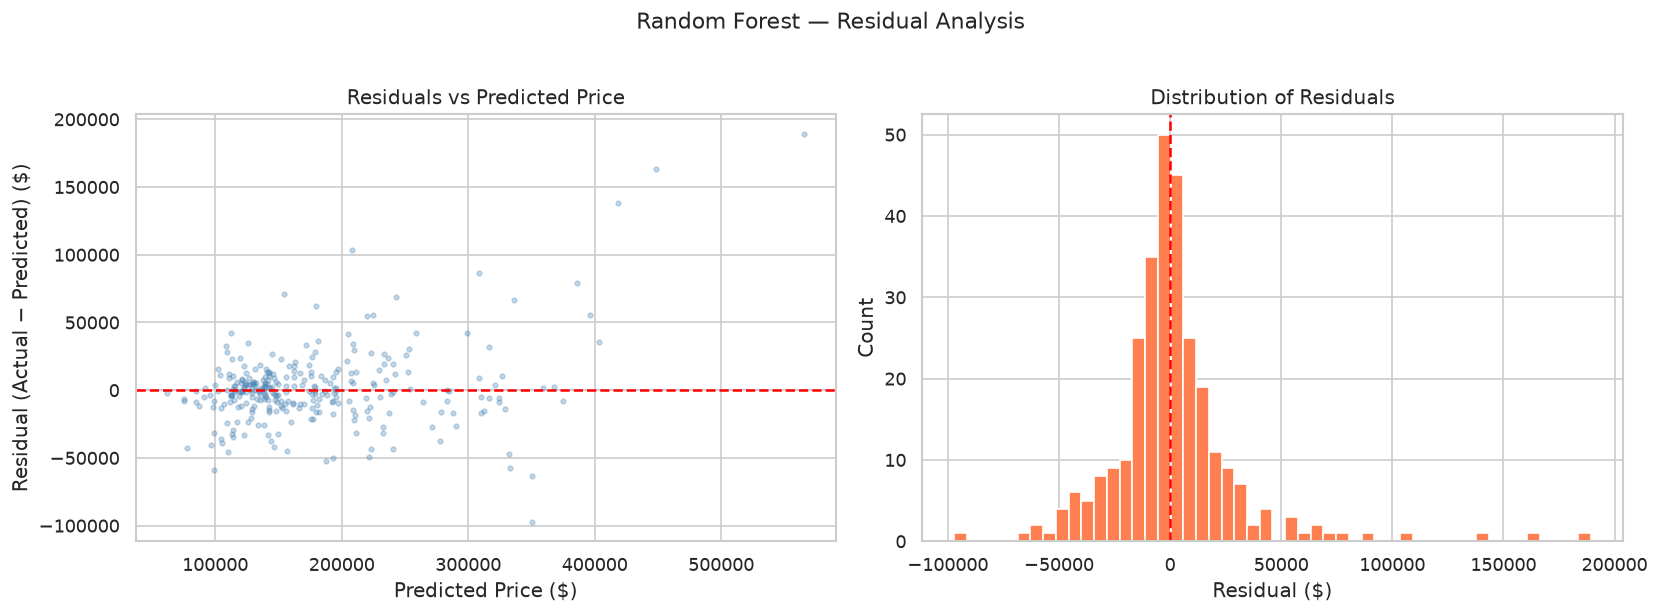

Mean residual  : $1,129  (should be close to 0)
Std of residuals: $28,792


In [15]:
# Residuals = actual price minus predicted price
# A good model should have residuals randomly scattered around 0
# Patterns in residuals = the model is systematically wrong somewhere

y_pred_rf = result_rf['predictions']
residuals  = y_test.values - y_pred_rf

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: residuals vs predicted — should look like a random cloud
axes[0].scatter(y_pred_rf, residuals, alpha=0.3, s=8, color='steelblue')
axes[0].axhline(0, color='red', linewidth=1.5, linestyle='--')
axes[0].set_title('Residuals vs Predicted Price')
axes[0].set_xlabel('Predicted Price ($)')
axes[0].set_ylabel('Residual (Actual − Predicted) ($)')

# Right: distribution of residuals — should be roughly bell-shaped around 0
axes[1].hist(residuals, bins=50, color='coral', edgecolor='white')
axes[1].axvline(0, color='red', linewidth=1.5, linestyle='--')
axes[1].set_title('Distribution of Residuals')
axes[1].set_xlabel('Residual ($)')
axes[1].set_ylabel('Count')

plt.suptitle('Random Forest — Residual Analysis', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "residual_analysis_rf.png", bbox_inches='tight')
plt.show()

print(f"Mean residual  : ${residuals.mean():,.0f}  (should be close to 0)")
print(f"Std of residuals: ${residuals.std():,.0f}")

In [16]:
# Save predictions alongside actual values — useful for reporting
preds_df = pd.DataFrame({
    'Actual_Price':    y_test.values,
    'RF_Predicted':    result_rf['predictions'],
    'Ridge_Predicted': result_ridge['fitted_model'].predict(X_test_scaled),
    'Tree_Predicted':  result_tree['fitted_model'].predict(X_test),
})
preds_df['RF_Error']    = preds_df['Actual_Price'] - preds_df['RF_Predicted']
preds_df['RF_Error_Pct'] = (preds_df['RF_Error'] / preds_df['Actual_Price'] * 100).abs()

preds_df.to_sql("model_predictions", con=engine, if_exists="replace", index=False)

print("Saved predictions to SQLite: table 'model_predictions'")
print(f"\nRandom Forest average % error: {preds_df['RF_Error_Pct'].mean():.1f}%")
print(f"Predictions within 10% of actual: "
      f"{(preds_df['RF_Error_Pct'] < 10).sum()} / {len(preds_df)} houses")

Saved predictions to SQLite: table 'model_predictions'

Random Forest average % error: 10.8%
Predictions within 10% of actual: 193 / 292 houses
